# Testing analog Hawking radiation in polariton fluids

The Paris-LKB experiment reported smooth acoustic horizons and measured excitation dispersions. The smooth-horizon gradient gives a nominal Hawking temperature scale. The calculations below illustrate a proposed stimulated measurement using the registered device parameters.

In [1]:
from src.core.constants import POLARITON_PLATFORMS
from src.core.formulas import (
    dispersive_hawking_correction,
    polariton_hawking_temperature,
    stimulated_hawking_gain,
    stimulated_hawking_snr,
)
from src.core.visualizations import fig_stimulated_hawking_spectrum

## Device inputs

The registered Paris smooth-horizon sound speed is 0.40 micrometers per picosecond with the reservoir included. The 300 ps cavity is a projection at fixed horizon parameters.

In [2]:
paris = POLARITON_PLATFORMS['Paris_ultralong']
T_H = polariton_hawking_temperature(kappa=paris['kappa'])
print(f"Nominal smooth-horizon temperature scale: {T_H*1e3:.1f} mK")

Nominal smooth-horizon temperature scale: 85.1 mK


## Stimulated gain in an idealized model

A coherent probe can stimulate emission. The illustration assumes unit greybody transmission and ideal shot-noise scaling. The full quadratic dispersive law is adopted for comparison. The plot and calculation use the effective frequency coordinate.

In [3]:
kappa = paris['kappa']
D = paris['xi'] * kappa / paris['c_s']
kappa_eff = kappa * dispersive_hawking_correction(D)
omega = 0.1 * kappa_eff
gain = stimulated_hawking_gain(omega, kappa_eff)
snr = stimulated_hawking_snr(omega, kappa_eff, n_probe=100, n_shots=1)

print(f"Projected 300 ps illustration at omega/kappa_eff = {omega/kappa_eff:.2f}")
print(f"  Unit-greybody model gain = {gain:.2f}")
print(f"  Ideal shot-noise SNR for 100 probe photons = {snr:.1f}")

Projected 300 ps illustration at omega/kappa_eff = 0.10
  Unit-greybody model gain = 1.14
  Ideal shot-noise SNR for 100 probe photons = 11.4


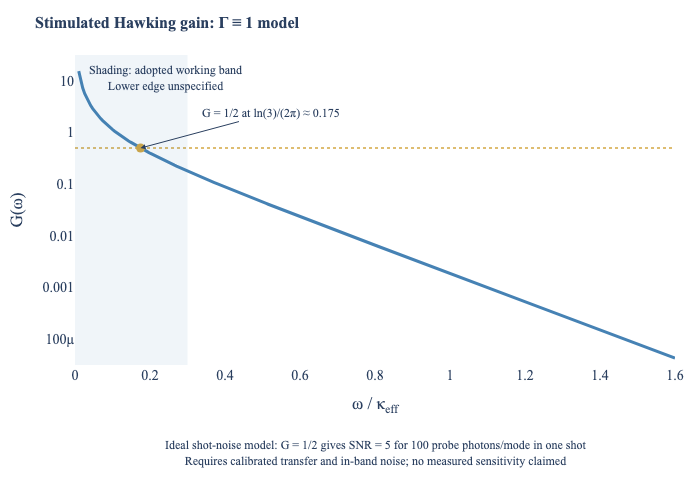

In [4]:
# viz-ref: fig_stimulated_hawking_spectrum
fig = fig_stimulated_hawking_spectrum()
fig.show()

## Cavity loss

The 8 ps cavity is the measured Paris configuration. The 100 ps and 300 ps configurations are projections. The ratio of polariton decay to surface gravity tests the necessary weak-loss criterion used by this model.

In [5]:
for name, params in POLARITON_PLATFORMS.items():
    if not name.startswith('Paris_'):
        continue
    ratio = params['Gamma_pol'] / params['kappa']
    device = 'measured cavity' if name == 'Paris_standard' else 'projected cavity'
    print(f"{name}: {device}; Gamma_pol/kappa = {ratio:.3f}; weak-loss criterion met: {ratio < 0.1}")

Paris_long: projected cavity; Gamma_pol/kappa = 0.143; weak-loss criterion met: False
Paris_ultralong: projected cavity; Gamma_pol/kappa = 0.048; weak-loss criterion met: True
Paris_standard: measured cavity; Gamma_pol/kappa = 1.786; weak-loss criterion met: False


## What the measurement needs

Testing the gain spectrum requires measured transmission, calibrated transfer and an instrument noise budget over a usable band. The shaded working band in the plot is an adopted illustration. Its lower edge and a physical error bound remain to be established.